| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_2_Modelos.ipynb) | [⏩](../11_MACHINE_LEARNING/11_4_Statistical_Learning_Theory.ipynb) |

# 11.3 Aprendizaje no supervisado: PCA, agrupamiento y anomalías

**Objetivo del cuaderno.** descubrir estructura sin etiquetas, construir coordenadas reducidas de campos científicos y revisar la estabilidad de grupos

**Antes de empezar:** SVD, covarianza, distancias y estadística. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report

## 1. ¿Qué se aprende cuando no hay etiquetas?

Disponemos de $X\in\mathbb R^{n\times d}$, pero no de respuestas objetivo. Podemos reducir dimensión, agrupar observaciones o identificar casos inusuales. Estas tareas no descubren automáticamente categorías naturales: dependen de representación, distancia y objetivo.

En SciML una fila puede ser una simulación y una columna un punto de una malla. Los métodos no supervisados permiten encontrar patrones dominantes antes de entrenar un surrogate. El conocimiento físico sigue siendo necesario para dar significado a los patrones.

## 2. PCA: encontrar direcciones de máxima variación

Con datos centrados $X_c=X-\mathbf1\bar x^T$, la descomposición $X_c=U\Sigma V^T$ da direcciones principales en las columnas de $V$. Las coordenadas de rango $r$ son $Z=X_cV_r$ y la reconstrucción es

$$\hat X=ZV_r^T+\mathbf1\bar x^T.$$

La proyección minimiza el error cuadrático entre aproximaciones lineales de rango $r$ en norma euclídea. Varianza explicada mide variación conservada en esa métrica, no exactitud física completa. Un modo poco energético puede ser decisivo para una inestabilidad.

## 3. Centrar, escalar y elegir una métrica

Centrar elimina la media; escalar modifica el peso relativo de variables. Si columnas representan la misma magnitud sobre una malla uniforme, una escala común puede tener sentido. Si mezclan presión y velocidad, estandarizar o usar una norma física ponderada es una elección de modelamiento.

PCA y estandarización deben ajustarse solo con entrenamiento si luego evaluamos reconstrucción de nuevos campos. Los ejes PCA pueden cambiar de signo sin cambiar el subespacio ni la reconstrucción.

## 4. Ejemplo: snapshots de un campo espacial

Creamos campos sobre $x\in[0,1]$ combinando tres modos suaves más ruido pequeño. Es una familia sintética de campos con estructura conocida, útil para comparar la reducción con una verdad controlada. Reservamos filas completas: cada fila es un campo.

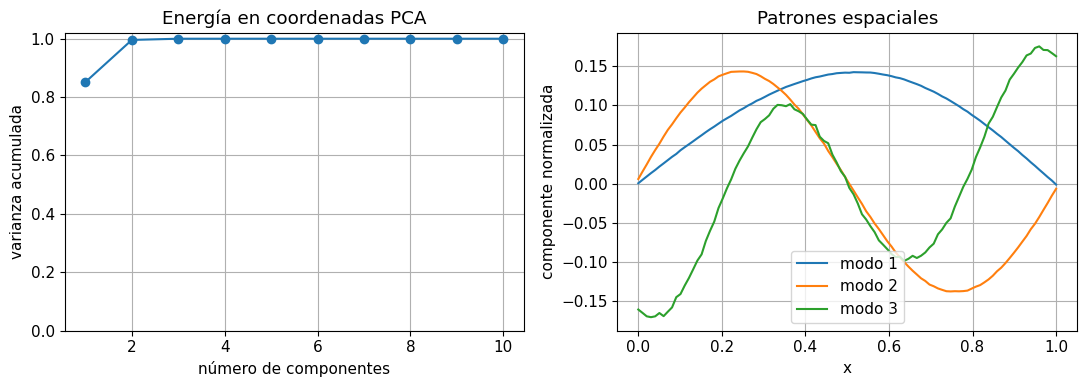

In [2]:
from sklearn.decomposition import PCA
space=np.linspace(0,1,100)
modes=np.array([np.sin(np.pi*space),np.sin(2*np.pi*space),np.cos(3*np.pi*space)])
coeff=rng.normal(size=(90,3))*np.array([2.,0.7,0.15])
fields=0.2+coeff@modes+rng.normal(0,0.015,(90,len(space)))
F_train,F_test=train_test_split(fields,test_size=0.25,random_state=5)
pca=PCA(n_components=10).fit(F_train)
coordinates=pca.transform(F_test)
reconstructed=pca.inverse_transform(coordinates)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(np.arange(1,11),np.cumsum(pca.explained_variance_ratio_),'o-')
ax[0].set(xlabel='número de componentes',ylabel='varianza acumulada',title='Energía en coordenadas PCA',ylim=(0,1.02))
for j in range(3):ax[1].plot(space,pca.components_[j],label=f'modo {j+1}')
ax[1].set(xlabel='x',ylabel='componente normalizada',title='Patrones espaciales');ax[1].legend()
plt.tight_layout();plt.show()

**Interpretación.** Las primeras componentes retienen casi toda la variación porque la familia fue construida con tres modos. Los componentes pueden mezclar los modos originales si los coeficientes tienen covarianza finita o si las funciones no son ortogonales en la malla. PCA identifica un subespacio útil, no necesariamente una base física única.

## 5. Reconstrucción y error fuera de entrenamiento

Para evaluar rango, reconstruimos campos reservados con diferentes cantidades de componentes. El error debe reducirse al ampliar un subespacio anidado, pero retener ruido añade complejidad sin una gran mejora física. Un rango útil equilibra precisión requerida y coste.

rango 1 error relativo reservado= 0.25589251096696575
rango 2 error relativo reservado= 0.04679529875208137
rango 3 error relativo reservado= 0.009990529403266448
rango 5 error relativo reservado= 0.009889088727589469
rango 10 error relativo reservado= 0.00966860218275127


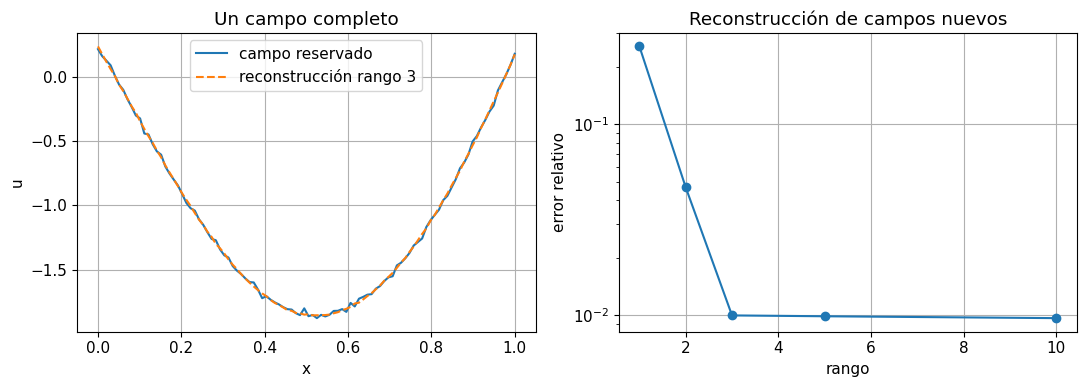

In [3]:
ranks=[1,2,3,5,10];errors=[]
for rank in ranks:
    model=PCA(n_components=rank).fit(F_train)
    rec=model.inverse_transform(model.transform(F_test))
    errors.append(np.linalg.norm(rec-F_test)/np.linalg.norm(F_test))
    print('rango',rank,'error relativo reservado=',errors[-1])
model3=PCA(n_components=3).fit(F_train)
rec3=model3.inverse_transform(model3.transform(F_test))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(space,F_test[0],label='campo reservado');ax[0].plot(space,rec3[0],'--',label='reconstrucción rango 3')
ax[0].set(xlabel='x',ylabel='u',title='Un campo completo');ax[0].legend()
ax[1].semilogy(ranks,errors,'o-');ax[1].set(xlabel='rango',ylabel='error relativo',title='Reconstrucción de campos nuevos')
plt.tight_layout();plt.show()
assert errors[-1] <= errors[0]

## 6. k-means: centroides y distancia euclídea

k-means busca centroides $c_j$ y asignaciones $z_i$ que minimizan

$$\sum_i\|x_i-c_{z_i}\|^2.$$

Alterna asignar cada punto al centro más cercano y actualizar centros por medias. Cada alternancia no aumenta el objetivo, pero puede acabar en un mínimo local. Las inicializaciones múltiples y `k-means++` ayudan; el número $k$ sigue siendo una decisión externa.

Funciona mejor para grupos compactos de escalas comparables. No modela naturalmente grupos en forma de anillos ni densidades muy diferentes. En datos científicos los centroides pueden representar regímenes promedio, pero las etiquetas numéricas de clusters son arbitrarias.

## 7. Agrupamiento e inspección de geometría

Generamos tres grupos para aprender el mecanismo. Conocemos sus etiquetas solo como referencia de este ejercicio; el algoritmo recibe únicamente las entradas. Estandarizamos porque la distancia debe comparar escalas.

Silhouette: 0.7151912340872842
ARI con etiquetas sintéticas: 0.9628935936243791


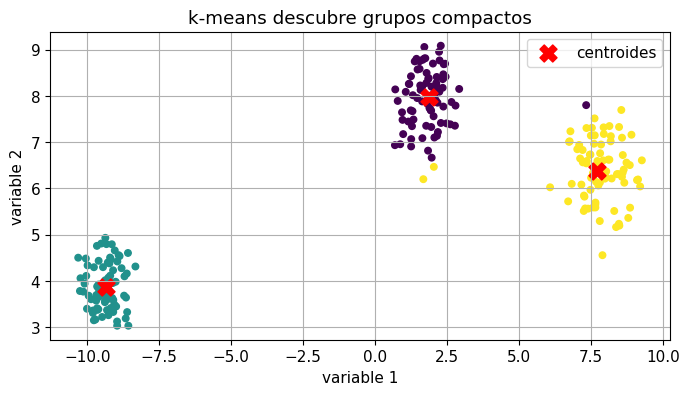

In [4]:
from sklearn.datasets import make_blobs,make_moons
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score,adjusted_rand_score
X,true_labels=make_blobs(n_samples=240,centers=3,cluster_std=[0.55,0.7,0.5],random_state=20)
scaler=StandardScaler();Xs=scaler.fit_transform(X)
km=KMeans(n_clusters=3,n_init=15,random_state=21).fit(Xs)
centers=scaler.inverse_transform(km.cluster_centers_)
plt.scatter(X[:,0],X[:,1],c=km.labels_,cmap='viridis',s=22)
plt.scatter(centers[:,0],centers[:,1],c='red',marker='X',s=150,label='centroides')
plt.xlabel('variable 1');plt.ylabel('variable 2');plt.title('k-means descubre grupos compactos');plt.legend();plt.show()
print('Silhouette:',silhouette_score(Xs,km.labels_))
print('ARI con etiquetas sintéticas:',adjusted_rand_score(true_labels,km.labels_))

## 8. Silhouette y estabilidad: diagnósticos parciales

Silhouette compara distancia media interna $a_i$ con distancia al grupo vecino $b_i$: $s_i=(b_i-a_i)/\max(a_i,b_i)$. Valores altos indican separación geométrica según la distancia usada; no prueban que las agrupaciones tengan significado científico.

ARI compara particiones sin depender del nombre de las etiquetas y corrige coincidencia esperada al azar. Aquí lo calculamos porque tenemos referencia sintética. En datos reales conviene estudiar estabilidad ante perturbaciones, resampling y cambios de escalado, además de interpretar perfiles físicos de grupos.

In [5]:
for k in [2,3,4,5]:
    labels=KMeans(n_clusters=k,n_init=10,random_state=8).fit_predict(Xs)
    print('k=',k,'silhouette=',round(silhouette_score(Xs,labels),3))
perturbed=Xs+rng.normal(0,0.03,Xs.shape)
labels2=KMeans(n_clusters=3,n_init=10,random_state=9).fit_predict(perturbed)
print('Estabilidad ARI tras perturbación pequeña:',adjusted_rand_score(km.labels_,labels2))

k= 2 silhouette= 0.753
k= 3 silhouette= 0.715
k= 4 silhouette= 0.65
k= 5 silhouette= 0.634
Estabilidad ARI tras perturbación pequeña: 1.0


## 9. DBSCAN y grupos de geometría curva

DBSCAN conecta regiones densas a partir de radio `eps` y número mínimo de vecinos `min_samples`. Puede descubrir formas no convexas y marcar ruido con etiqueta $-1$. Sus resultados dependen de escala y densidad: un único radio puede no servir para densidades muy diferentes.

Comparamos sobre lunas, donde k-means fuerza regiones alrededor de centroides y DBSCAN usa conectividad local. Los hiperparámetros de este ejemplo son ilustrativos; no garantizan resultados para otra distribución.

Puntos considerados ruido por DBSCAN: 0


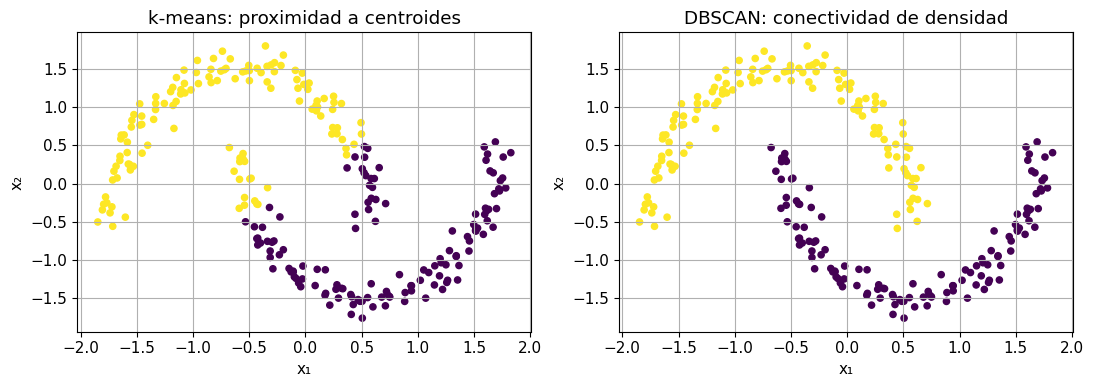

In [6]:
moon,_=make_moons(n_samples=260,noise=0.06,random_state=2)
moon=StandardScaler().fit_transform(moon)
labels_k=KMeans(n_clusters=2,n_init=15,random_state=3).fit_predict(moon)
labels_d=DBSCAN(eps=0.25,min_samples=5).fit_predict(moon)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for a,labels,title in zip(ax,[labels_k,labels_d],['k-means: proximidad a centroides','DBSCAN: conectividad de densidad']):
    a.scatter(moon[:,0],moon[:,1],c=labels,cmap='viridis',s=20);a.set(title=title,xlabel='x₁',ylabel='x₂')
plt.tight_layout();plt.show()
print('Puntos considerados ruido por DBSCAN:',np.sum(labels_d==-1))

**Interpretación.** La geometría de los datos determina si una idea de grupo es adecuada. Una frontera lineal entre centroides puede atravesar las lunas, mientras la conectividad densa puede seguir su curva. No existe una definición única de cluster válida para todo objetivo.

## 10. Anomalías por error de reconstrucción

Un campo muy diferente de los modos aprendidos puede tener un error PCA grande. Este error es un indicador de desviación respecto al subespacio, no una prueba automática de fallo. Una anomalía también puede ser una física nueva, un sensor mal calibrado o una condición inicial no representada.

Construimos un campo con oscilaciones fuera de la base. El umbral se obtiene de entrenamiento solo con finalidad demostrativa; para detectar fallos reales debe calibrarse con validación y costes de falsas alarmas.

In [7]:
train_rec=model3.inverse_transform(model3.transform(F_train))
train_rmse=np.sqrt(np.mean((F_train-train_rec)**2,axis=1))
threshold=np.quantile(train_rmse,0.99)
anomaly=F_test[0]+0.4*np.sin(17*np.pi*space)
anomaly_rec=model3.inverse_transform(model3.transform(anomaly[None,:]))[0]
anomaly_rmse=np.sqrt(np.mean((anomaly-anomaly_rec)**2))
print('Umbral demostrativo train:',threshold,'Error del campo perturbado:',anomaly_rmse)
assert anomaly_rmse>threshold

Umbral demostrativo train: 0.01698719432995458 Error del campo perturbado: 0.2832129340469185


## Síntesis y conexión con Scientific Machine Learning

PCA aprende un subespacio, k-means aprende centroides y DBSCAN aprende conectividad de densidad. Ninguno sustituye la interpretación física. La reducción de snapshots es un puente directo a POD y modelos de orden reducido, siempre con evaluación de campos completos reservados.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_2_Modelos.ipynb) | [⏩](../11_MACHINE_LEARNING/11_4_Statistical_Learning_Theory.ipynb) |